# Electricity Demand Analysis

### 전력수요 패턴 및 변동성 분석과 머신러닝 예측

한국전력거래소(KPX)의 2025년 전국 시간별 전력수요 데이터를 활용하여 수요의 주기적 패턴과 변동성을 분석하고, 피크·급변·이례 구간을 탐색한다.  
또한 머신러닝 모델의 예측 성능을 비교하여 전력수요 모니터링에 활용할 수 있는 지표를 도출한다.

## 프로젝트 개요

- **분석 데이터:** 한국전력거래소(KPX)의 2025년 전국 시간별 전력수요 데이터(8,760개 시간별 관측값)
- **분석 목표:** 전력수요의 피크 집중도, 시간별 급변 구간 및 평상시 패턴에서 벗어나는 이례 신호 파악
- **분석 및 활용:** 시계열 특성 분석과 통계적 지표 산출을 중심으로 운영 모니터링 가능성을 검토하고, 머신러닝 모델의 예측 성능을 보조적으로 평가

## 주요 분석 내용

1. **데이터 전처리:** 결측치·중복값 검증 및 시계열 데이터 정제
2. **전력수요 패턴 분석:** 월별·요일별·시간대별 수요 특성 파악
3. **피크 및 변동성 분석:** 피크 수요 집중도와 시간별 수요 변화량 분석
4. **이례 패턴 탐색:** 통계적 기준선을 활용한 이례 수요 구간 탐색
5. **머신러닝 예측:** 회귀·앙상블 모델 학습 및 예측 성능 비교

## 개발 환경

- **언어:** Python
- **라이브러리:** Pandas, NumPy, Matplotlib, scikit-learn
- **실행 환경:** Google Colab

### 데이터 출처

- **제공 기관:** 한국전력거래소(KPX)
- **데이터명:** [2025년 시간별 전국 전력수요량](https://www.data.go.kr/data/15065266/fileData.do)
- **데이터 범위:** 2025년 1월~12월, 전국(육지·제주 포함) 시간별 전력수요 데이터
- **원본 파일:** `data/kpx_hourly_demand_2025.csv`

In [128]:
from pathlib import Path
import os

# Colab에서는 기존 Google Drive 경로를 사용하고, 로컬에서는 노트북 폴더를 사용합니다.
if 'google.colab' in __import__('sys').modules or 'COLAB_RELEASE_TAG' in os.environ:
    from google.colab import drive
    drive.mount('/content/drive')
    project_dir = Path('/content/drive/MyDrive/Electricity-Demand-Analysis')
else:
    project_dir = Path.cwd()

if not project_dir.is_dir():
    raise FileNotFoundError(f'프로젝트 폴더를 찾을 수 없습니다: {project_dir}')

os.chdir(project_dir)

print('프로젝트 경로:', Path.cwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
프로젝트 경로: /content/drive/MyDrive/Electricity-Demand-Analysis


In [129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
import sklearn

plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.grid'] = True
file_path = Path('data/kpx_hourly_demand_2025.csv')
if not file_path.is_file():
    raise FileNotFoundError(f'원본 CSV가 없습니다: {Path.cwd() / file_path}')
raw = pd.read_csv(file_path, encoding='cp949', index_col=False)
print('Original shape:', raw.shape)
display(raw.head())

Original shape: (366, 25)


,날짜,1시,2시,3시,4시,5시,6시,7시,8시,9시,...,15시,16시,17시,18시,19시,20시,21시,22시,23시,24시
0,2025-01-01,62256.0,59663.0,57880.0,57098.0,56966.0,57442.0,58338.0,58868.0,58090.0,...,49914.0,53489.0,58061.0,62545.0,64403.0,64403.0,63653.0,62722.0,62249.0,61871.0
1,2025-01-02,59219.0,57092.0,55931.0,55597.0,56374.0,58691.0,63081.0,70103.0,77832.0,...,70016.0,73169.0,76318.0,77503.0,76379.0,74902.0,72276.0,69663.0,69473.0,68787.0
2,2025-01-03,65330.0,63074.0,61755.0,60993.0,61499.0,63432.0,67664.0,74049.0,80523.0,...,73431.0,76306.0,78869.0,79167.0,77242.0,75448.0,73036.0,70538.0,70455.0,69823.0
3,2025-01-04,66212.0,63730.0,62110.0,61330.0,61280.0,62336.0,63885.0,65585.0,66303.0,...,57926.0,60564.0,64045.0,67049.0,68094.0,67459.0,66352.0,64800.0,65825.0,66178.0
4,2025-01-05,63136.0,60441.0,58702.0,57840.0,57795.0,58438.0,59510.0,60502.0,61796.0,...,63051.0,63464.0,64652.0,67227.0,67984.0,67151.0,65972.0,64410.0,64053.0,63852.0


## 1. 데이터 품질 검증 및 시계열 변환

### 분석 목적

전력수요 데이터의 시간별 변환 및 결측치·중복값·시간축 검증을 통한 데이터 신뢰성 확보

### 데이터 전처리

- **불필요한 행 제거:** 날짜 정보가 없는 빈 행을 제거하여 유효한 관측값만 유지
- **날짜 형식 변환:** 문자열 형태의 날짜를 날짜형 데이터로 변환하여 시계열 정렬 및 날짜별 특성 추출
- **데이터 구조 변환:** 하루 1행에 24개 시간대가 열로 구성된 Wide Format을 시간별 1행의 Long Format으로 변환
- **수요 데이터 형식 변환:** 시간별 전력수요를 숫자형으로 변환하여 통계 분석 및 모델 학습에 활용
- **시간축 정규화:** 원본의 1시부터 24시까지의 시간 구간을 분석용 0시부터 23시까지의 시간 슬롯에 대응시켜 일관된 시간축 구성

### 데이터 품질 검증

- **결측치 검사:** 날짜 및 전력수요 데이터의 누락 여부 확인
- **중복값 검사:** 동일 날짜와 시간대의 중복 관측값 확인
- **시간대 완전성 확인:** 날짜별 24개 시간대의 관측값 존재 여부 검증
- **시계열 일관성 확인:** 날짜 및 시간대 순서에 따른 데이터 정렬 상태 점검

### 전처리 기준

결측값과 중복값을 검사하여 데이터의 정확성을 확인하고, 원본 관측값은 임의로 변경하지 않는다.

원본의 시간 구간을 분석용 시간 슬롯에 대응시켜 일관된 시계열 데이터를 구성한다.  
해당 변환은 분석을 위한 기준이며, 실제 관측 시간의 정의는 데이터 제공기관의 기준을 따른다.

In [130]:
print('Null counts (including blank row):', raw.isna().sum().sum())
raw = raw.dropna(subset=['날짜']).copy()
raw['날짜'] = pd.to_datetime(raw['날짜'], errors='coerce')
assert raw['날짜'].notna().all()
assert raw['날짜'].is_unique
hours = [f'{h}시' for h in range(1,25)]
for h in hours: raw[h] = pd.to_numeric(raw[h], errors='coerce')
print('Valid days:', len(raw), 'Missing demand values:', int(raw[hours].isna().sum().sum()))
df = raw.melt(id_vars='날짜', value_vars=hours, var_name='hour_label', value_name='demand_mwh')
df['hour'] = df['hour_label'].str.replace('시','',regex=False).astype(int)
df['timestamp'] = df['날짜'] + pd.to_timedelta(df['hour']-1, unit='h')
df = df.sort_values('timestamp').reset_index(drop=True)
df['month'] = df['timestamp'].dt.month
df['weekday'] = df['timestamp'].dt.dayofweek
df['is_weekend'] = (df['weekday']>=5).astype(int)
df['season'] = df['month'].map({12:'Winter',1:'Winter',2:'Winter',3:'Spring',4:'Spring',5:'Spring',6:'Summer',7:'Summer',8:'Summer',9:'Autumn',10:'Autumn',11:'Autumn'})
assert len(df)==365*24 and df['demand_mwh'].notna().all()
print('Hourly records:',len(df),'Date range:',df.timestamp.min(),df.timestamp.max())
display(df.head())

Null counts (including blank row): 25
Valid days: 365 Missing demand values: 0
Hourly records: 8760 Date range: 2025-01-01 00:00:00 2025-12-31 23:00:00


,날짜,hour_label,demand_mwh,hour,timestamp,month,weekday,is_weekend,season
0,2025-01-01,1시,62256.0,1,2025-01-01 00:00:00,1,2,0,Winter
1,2025-01-01,2시,59663.0,2,2025-01-01 01:00:00,1,2,0,Winter
2,2025-01-01,3시,57880.0,3,2025-01-01 02:00:00,1,2,0,Winter
3,2025-01-01,4시,57098.0,4,2025-01-01 03:00:00,1,2,0,Winter
4,2025-01-01,5시,56966.0,5,2025-01-01 04:00:00,1,2,0,Winter


## 2. 전력수요 기초통계 및 극값 분석

### 분석 목적

전력수요의 분포·변동 특성, 최대·최소 수요 발생 시점 및 평일·주말 수요 차이 파악

### 분석 방법

- **기초통계 분석:** 평균, 중앙값, 사분위수 및 표준편차를 산출하여 전력수요의 분포와 변동 수준 확인
- **최대·최소 수요 분석:** 전력수요의 최댓값과 최솟값 및 발생 시점 확인
- **평일·주말 수요 비교:** 평일과 주말의 평균 전력수요를 비교하여 집단 간 차이 파악
- **데이터 완전성 검증:** 365일의 데이터가 포함되어 있는지, 날짜별로 24개의 시간별 관측값이 존재하는지 확인

### 결과 해석

기초통계와 극값을 통해 전력수요의 전반적인 수준과 변동 범위를 확인하고, 평일과 주말의 평균 수요 차이를 통해 요일에 따른 수요 특성을 탐색한다.

다만 집단 간 평균 차이나 극값의 발생 원인을 해당 통계만으로 특정할 수는 없으며, 구체적인 원인 분석에는 추가적인 외부 데이터가 필요하다

In [131]:
display(df['demand_mwh'].describe().to_frame('Demand (MWh)'))
for label, row in [('Maximum',df.loc[df.demand_mwh.idxmax()]),('Minimum',df.loc[df.demand_mwh.idxmin()])]:
    print(label, row.timestamp, f'{row.demand_mwh:,.0f} MWh')
print('Weekday mean:',round(df.loc[df.is_weekend==0,'demand_mwh'].mean(),1))
print('Weekend mean:',round(df.loc[df.is_weekend==1,'demand_mwh'].mean(),1))

,Demand (MWh)
count,8760.000000
mean,64503.260274
std,10116.983596
min,35811.000000
25%,57107.500000
50%,63400.000000
75%,71079.500000
max,95951.000000


Maximum 2025-08-25 17:00:00 95,951 MWh
Minimum 2025-05-04 11:00:00 35,811 MWh
Weekday mean: 66920.9
Weekend mean: 58435.9


## 3. 탐색적 데이터 분석(EDA)

### 분석 목적

2025년 전력수요의 연중 변화와 시간대·요일·계절별 반복 패턴 및 주요 특성 시각화

### 분석 방법

- **일별 평균 수요 추이:** 연중 전력수요의 변화 흐름과 수요가 집중되는 시기 확인
- **시간대별 평균 수요:** 하루 중 수요가 높거나 낮은 시간대 및 일중 패턴 분석
- **월별 평균 수요:** 월간 수요 수준을 비교하여 계절적 변화 특성 탐색
- **요일별 평균 수요:** 평일과 주말의 수요 차이 및 요일별 반복 패턴 확인
- **요일·시간대별 히트맵:** 요일과 시간대의 조합에 따른 수요 분포 및 특성 비교
- **계절별 시간대 수요 곡선:** 계절에 따른 일중 수요 패턴과 피크 시간대의 변화 분석

### 결과 해석

각 시각화 결과를 통해 전력수요의 주기적 변화와 시기별 특성을 확인하고, 피크 및 변동성 분석에 필요한 기초 정보를 확보한다.

다만 관측된 수요 변화의 원인을 정확히 파악하기 위해서는 기온, 공휴일, 산업 활동 등 추가적인 외부 데이터가 필요하다.  
따라서 시각화 결과만으로 특정 원인과의 인과관계를 단정하지 않는다.

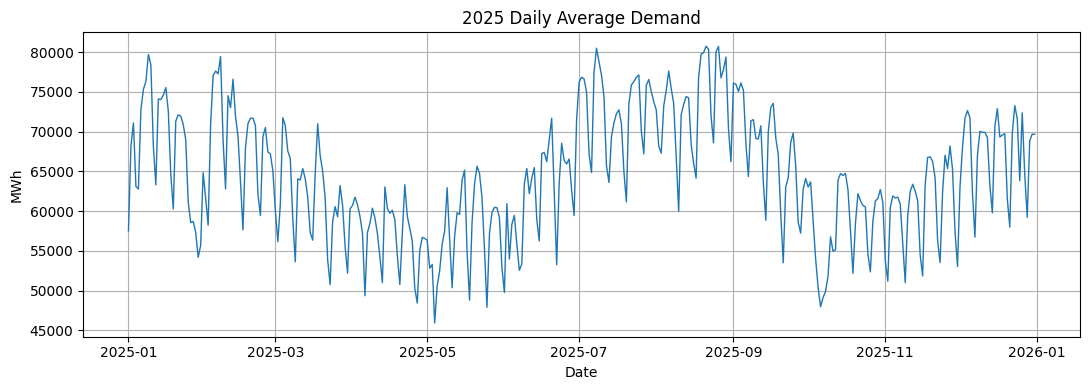

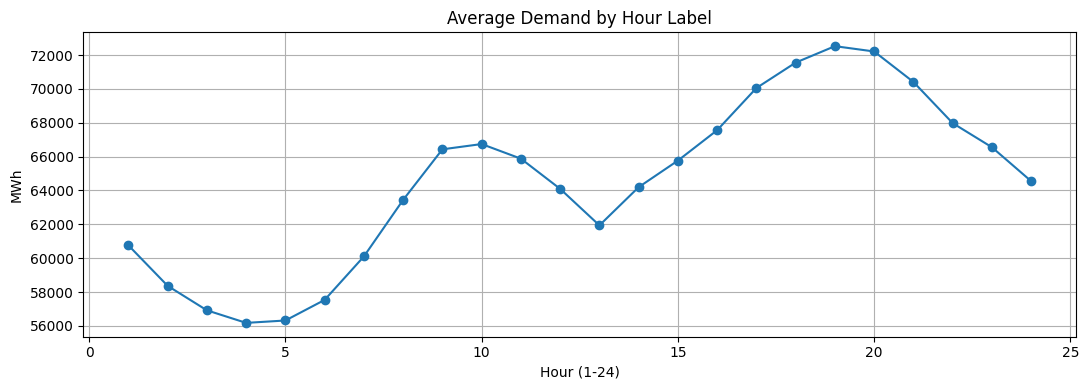

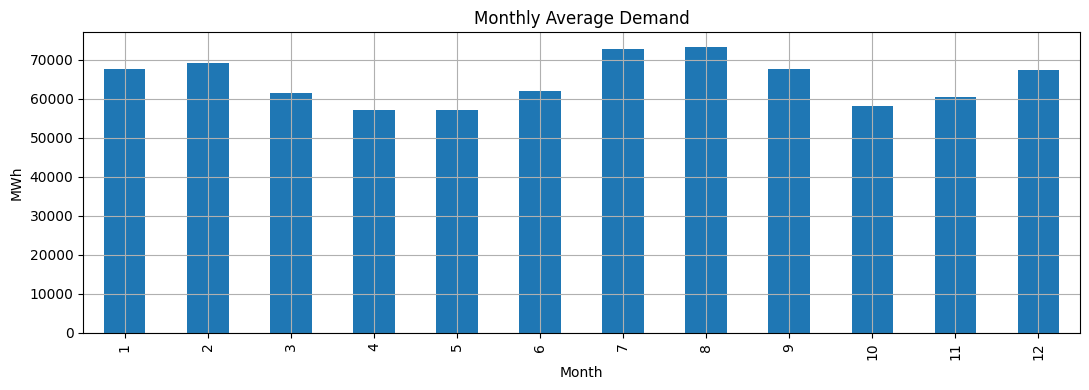

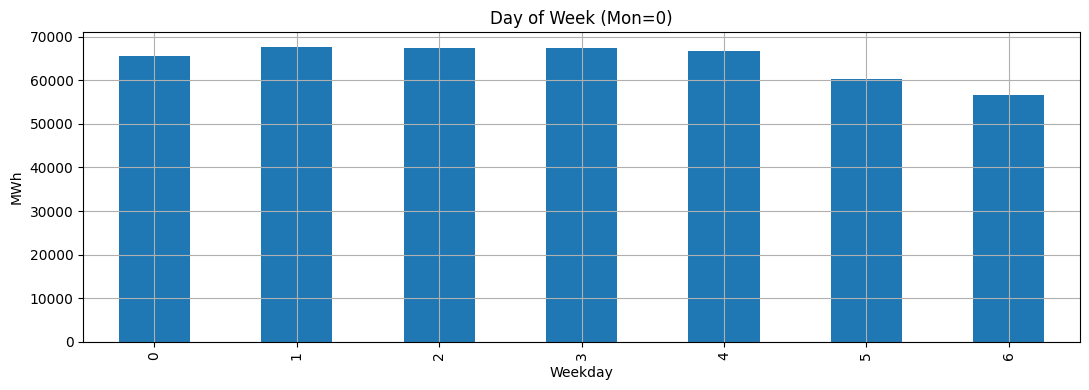

In [132]:
daily = df.groupby('날짜',as_index=False)['demand_mwh'].mean()
fig,ax=plt.subplots();ax.plot(daily['날짜'],daily.demand_mwh,lw=1);ax.set(title='2025 Daily Average Demand',xlabel='Date',ylabel='MWh');plt.tight_layout();plt.show()
fig,ax=plt.subplots();df.groupby('hour')['demand_mwh'].mean().plot(ax=ax,marker='o');ax.set(title='Average Demand by Hour Label',xlabel='Hour (1-24)',ylabel='MWh');plt.tight_layout();plt.show()
fig,ax=plt.subplots();df.groupby('month')['demand_mwh'].mean().plot(kind='bar',ax=ax);ax.set(title='Monthly Average Demand',xlabel='Month',ylabel='MWh');plt.tight_layout();plt.show()
fig,ax=plt.subplots();df.groupby('weekday')['demand_mwh'].mean().plot(kind='bar',ax=ax);ax.set(title='Day of Week (Mon=0)',xlabel='Weekday',ylabel='MWh');plt.tight_layout();plt.show()

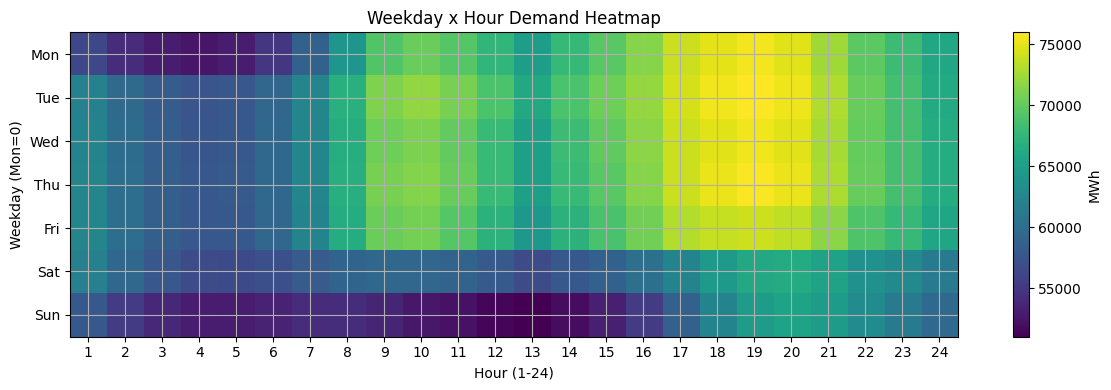

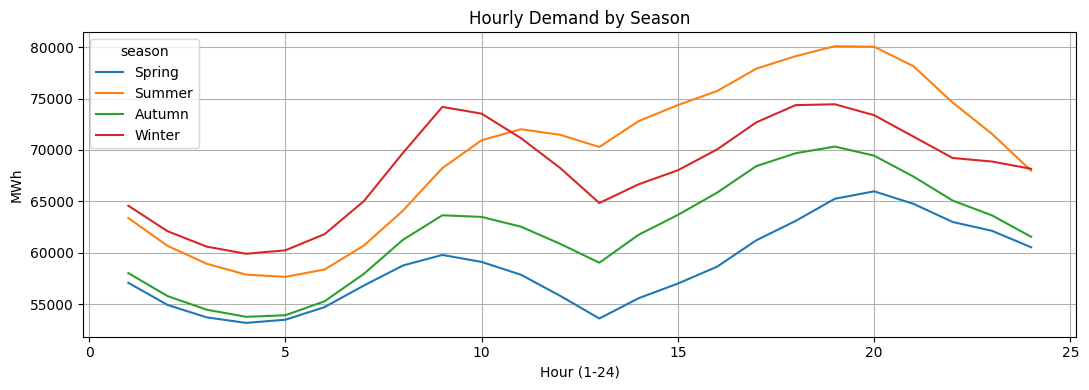

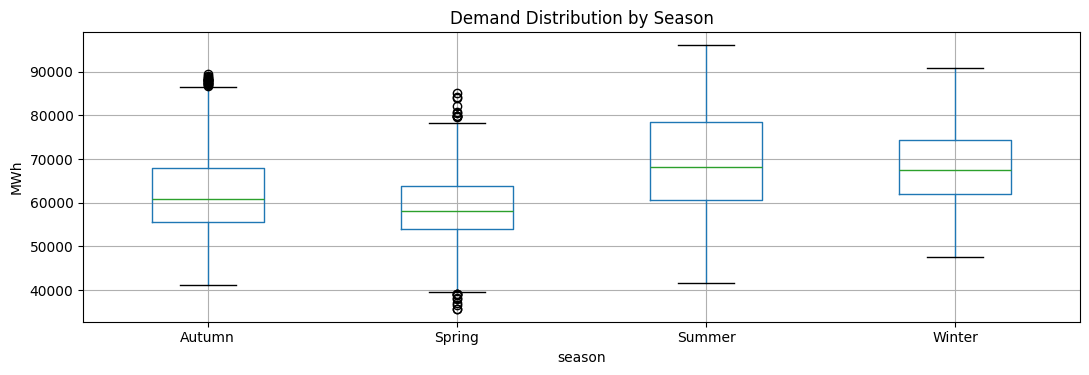

In [133]:
heat = df.pivot_table(index='weekday',columns='hour',values='demand_mwh',aggfunc='mean')
fig,ax=plt.subplots(figsize=(12,4));im=ax.imshow(heat,aspect='auto',cmap='viridis');ax.set(title='Weekday x Hour Demand Heatmap',xlabel='Hour (1-24)',ylabel='Weekday (Mon=0)');ax.set_xticks(range(24),range(1,25));ax.set_yticks(range(7),['Mon','Tue','Wed','Thu','Fri','Sat','Sun']);fig.colorbar(im,ax=ax,label='MWh');plt.tight_layout();plt.show()
season_hour=df.pivot_table(index='hour',columns='season',values='demand_mwh',aggfunc='mean')
fig,ax=plt.subplots();season_hour[['Spring','Summer','Autumn','Winter']].plot(ax=ax);ax.set(title='Hourly Demand by Season',xlabel='Hour (1-24)',ylabel='MWh');plt.tight_layout();plt.show()
fig,ax=plt.subplots();df.boxplot(column='demand_mwh',by='season',ax=ax);plt.suptitle('');ax.set(title='Demand Distribution by Season',ylabel='MWh');plt.tight_layout();plt.show()

## 4. 시간별 전력수요 변화량 분석

### 분석 목적

시간별 전력수요의 증감량 분석을 통한 급격한 수요 변화 시점 및 주요 변동 구간의 특성 파악

### 분석 방법

- **시간별 변화량 계산:** 현재 시간의 전력수요에서 직전 시간의 수요를 차감하여 증감량 산출
- **급변 구간 추출:** 변화량의 절댓값을 기준으로 수요 증가 및 감소 폭이 큰 구간 탐색
- **변동 특성 확인:** 주요 급변 구간의 발생 시점과 수요 변화 방향 비교

시간별 변화량은 `delta = demand(t) - demand(t-1)`로 계산하며, 양수는 수요 증가, 음수는 수요 감소를 의미한다.

### 결과 해석

변화량의 절댓값이 큰 구간은 단시간에 전력수요가 크게 변한 시점을 나타낸다.  
다만 이러한 변화는 일상적인 수요 패턴에서도 발생할 수 있으므로, 급변 자체를 이상 현상으로 단정하지 않는다.

급변 원인을 구체적으로 파악하기 위해서는 기상 조건, 공휴일 및 전력계통 상황 등 추가 데이터와의 비교가 필요하다.

,timestamp,demand_mwh,delta_mwh
128,2025-01-06 08:00:00,80157.0,8969.0
1496,2025-03-04 08:00:00,79627.0,8896.0
8527,2025-12-22 07:00:00,73580.0,8641.0
296,2025-01-13 08:00:00,83820.0,8482.0
464,2025-01-20 08:00:00,80585.0,8455.0
4496,2025-07-07 08:00:00,78894.0,8446.0
1016,2025-02-12 08:00:00,82816.0,8396.0
896,2025-02-07 08:00:00,85153.0,8309.0
200,2025-01-09 08:00:00,86700.0,8302.0
5696,2025-08-26 08:00:00,84299.0,8297.0


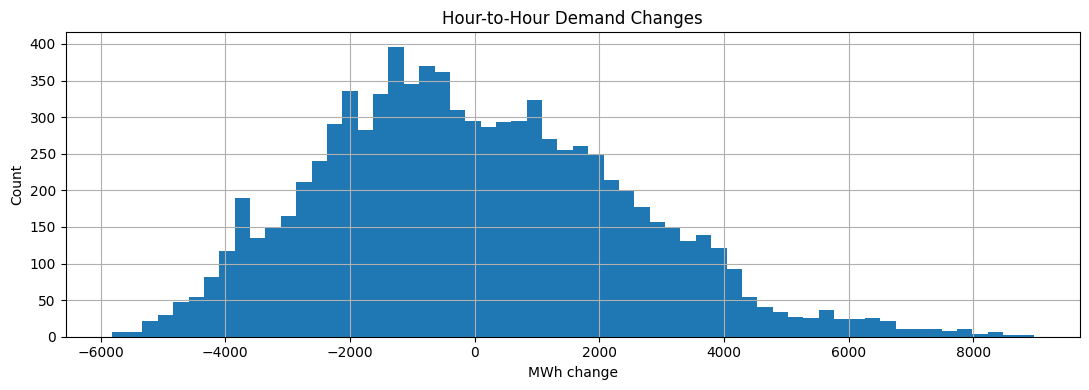

In [134]:
df['delta_mwh']=df.demand_mwh.diff()
df['abs_delta_mwh']=df.delta_mwh.abs()
display(df.nlargest(10,'abs_delta_mwh')[['timestamp','demand_mwh','delta_mwh']])
fig,ax=plt.subplots();ax.hist(df.delta_mwh.dropna(),bins=60);ax.set(title='Hour-to-Hour Demand Changes',xlabel='MWh change',ylabel='Count');plt.tight_layout();plt.show()

## 5. 머신러닝 기반 1시간 후 전력수요 예측

### 분석 목적

과거 전력수요 데이터를 활용한 1시간 후 수요 예측 및 머신러닝 모델별 성능 비교

### 예측 모델 설계

- **예측 대상:** 1시간 후 전력수요(MWh)
- **입력 변수:** 과거 1시간, 24시간, 168시간 전 수요(`lag_1`, `lag_24`, `lag_168`) 및 시간 관련 특성
- **데이터 분할:** 1월부터 9월까지 학습, 10월부터 11월까지 검증, 12월 최종 평가
- **비교 기준:** 직전 시간 수요(`lag_1`, 주 기준선) 및 전일 동일 시간 수요(`lag_24`, 보조 기준선)
- **정보 누출 방지:** 예측 시점에 확인할 수 없는 실제 수요 및 미래 통계값 제외

예측 시점에 직전 시간의 실제 수요값을 확보할 수 있다고 가정하며, 시간순 데이터 분할을 통해 미래 정보가 학습 과정에 유입되는 것을 방지한다.

### 모델 선정 및 비교

- **직전 시간 기준선:** 1시간 앞 예측에서 직전 수요를 그대로 사용하는 기본 비교 기준
- **전일 동일 시간 기준선:** 보조 비교 기준
- **Ridge 회귀:** 선형 관계를 기반으로 한 예측 성능 확인
- **Random Forest:** 결정트리 앙상블을 활용한 비선형 패턴 학습
- **Hist Gradient Boosting:** 부스팅 기반 앙상블 모델의 예측 성능 비교

전력수요는 연속형 수치이므로 분류가 아닌 회귀 모델을 적용하며, 단순 기준선과 머신러닝 모델의 성능을 함께 비교한다.

### 모델 성능 평가

- **MAE(평균 절대오차):** 실제 수요와 예측값 사이의 평균적인 오차 크기 평가
- **RMSE(평균 제곱근 오차):** 큰 예측 오차에 더 높은 가중치를 부여하여 평가
- **R²(결정계수):** 평균값 예측을 기준으로 모델의 설명력 평가

검증 데이터의 평가 결과를 바탕으로 최종 모델을 선정하고, 별도로 분리한 12월 테스트 데이터에서 예측 성능을 확인한다.

### 결과 해석

모델별 예측 오차와 결정계수를 비교하여 단순 기준선 대비 머신러닝 적용 효과를 평가한다.

최종 성능은 12월 테스트 기간에 대한 결과이므로, 다른 계절이나 장기 예측 상황에서도 동일한 성능이 유지된다고 일반화할 수는 없다.

In [135]:
df['lag_1']=df.demand_mwh.shift(1)
df['lag_24']=df.demand_mwh.shift(24)
df['lag_168']=df.demand_mwh.shift(168)
df['hour_sin']=np.sin(2*np.pi*(df.hour-1)/24)
df['hour_cos']=np.cos(2*np.pi*(df.hour-1)/24)
df['month_sin']=np.sin(2*np.pi*df.month/12)
df['month_cos']=np.cos(2*np.pi*df.month/12)
features=['lag_1','lag_24','lag_168','hour_sin','hour_cos','weekday','is_weekend','month_sin','month_cos']
model_df=df.dropna(subset=features+['demand_mwh']).copy()
train=model_df[model_df.timestamp<'2025-10-01'];valid=model_df[(model_df.timestamp>='2025-10-01')&(model_df.timestamp<'2025-12-01')];test=model_df[model_df.timestamp>='2025-12-01']
print('Train/validation/test:',len(train),len(valid),len(test))
ridge_preprocess=ColumnTransformer([
    ('numeric',StandardScaler(),[c for c in features if c!='weekday']),
    ('weekday',OneHotEncoder(handle_unknown='ignore'),['weekday'])])
models={'Ridge':make_pipeline(ridge_preprocess,Ridge(alpha=10)),
        'Random Forest':RandomForestRegressor(n_estimators=100,min_samples_leaf=3,max_depth=14,random_state=42,n_jobs=-1),
        'Hist Gradient Boosting':HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=20,learning_rate=0.08,random_state=42)}
def metrics(y,p):return {'MAE':mean_absolute_error(y,p),'RMSE':np.sqrt(mean_squared_error(y,p)),'R2':r2_score(y,p)}
val_results=[{'model':'Previous hour (baseline)',**metrics(valid.demand_mwh,valid.lag_1)},
             {'model':'Previous day (baseline)',**metrics(valid.demand_mwh,valid.lag_24)}]
for name,model in models.items():
    model.fit(train[features],train.demand_mwh)
    val_results.append({'model':name,**metrics(valid.demand_mwh,model.predict(valid[features]))})
val_table=pd.DataFrame(val_results).sort_values('MAE')
display(val_table.round(3))
selected=val_table[val_table.model.isin(models)].iloc[0]['model']
print('Selected on validation only:',selected)
print('scikit-learn version:',sklearn.__version__)

Train/validation/test: 6384 1464 744


,model,MAE,RMSE,R2
3,Random Forest,911.736,1226.890,0.973
4,Hist Gradient Boosting,915.340,1198.679,0.974
2,Ridge,1525.059,1927.511,0.932
0,Previous hour (baseline),1884.470,2258.579,0.907
1,Previous day (baseline),3532.189,5287.973,0.491


Selected on validation only: Random Forest
scikit-learn version: 1.6.1


,model,MAE,RMSE,R2
0,Previous hour (baseline),2244.190,2801.864,0.869
1,Previous day (baseline),5215.218,7479.592,0.065
2,Ridge,1718.885,2325.862,0.910
3,Random Forest (selected),860.486,1134.097,0.979
4,Hist Gradient Boosting,736.574,968.827,0.984


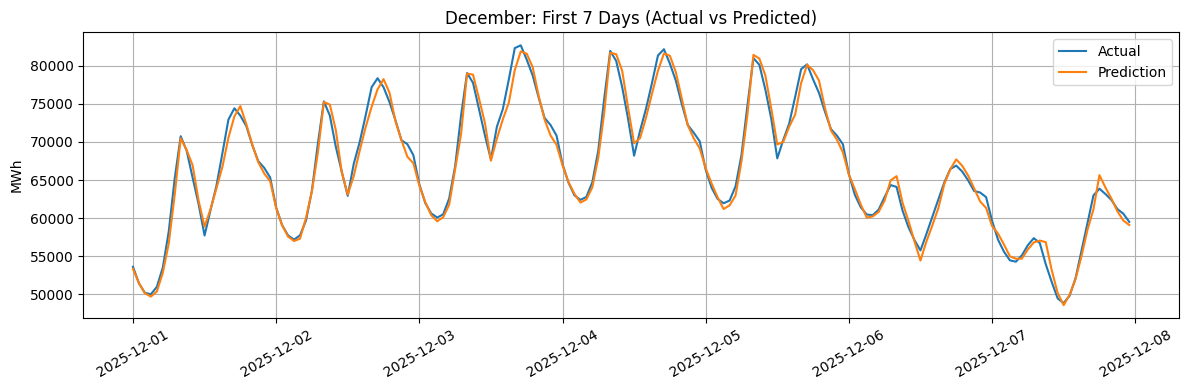

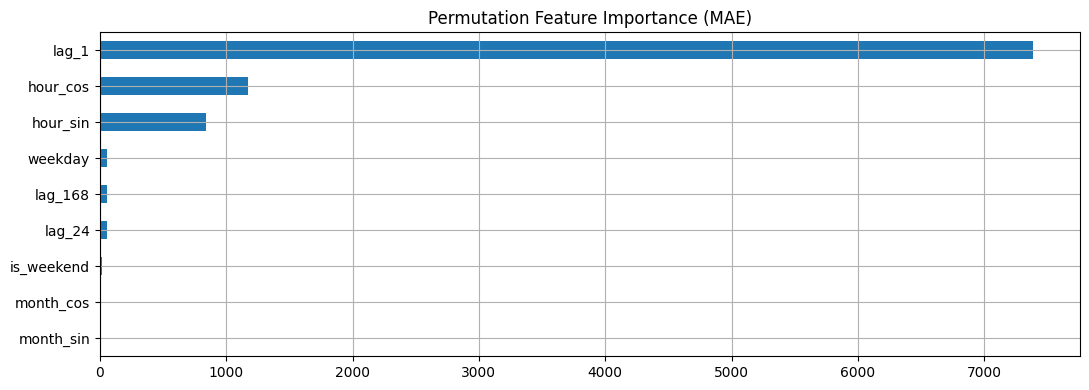

In [136]:
# 검증 데이터로 선정한 모델을 1~11월 데이터로 재학습
train_valid=model_df[model_df.timestamp<'2025-12-01']
chosen=models[selected]
chosen.fit(train_valid[features],train_valid.demand_mwh)
pred=chosen.predict(test[features])
final_rows=[{'model':'Previous hour (baseline)',**metrics(test.demand_mwh,test.lag_1)},
            {'model':'Previous day (baseline)',**metrics(test.demand_mwh,test.lag_24)}]
# 12월 데이터는 모델별 성능 비교에만 사용
for name,model in models.items():
    if name==selected:
        model_pred=pred
    else:
        from sklearn.base import clone
        refit=clone(model).fit(train_valid[features],train_valid.demand_mwh)
        model_pred=refit.predict(test[features])
    final_rows.append({'model':name+(' (selected)' if name==selected else ''),**metrics(test.demand_mwh,model_pred)})
final_table=pd.DataFrame(final_rows)
display(final_table.round(3))
fig,ax=plt.subplots(figsize=(12,4));subset=test.iloc[:24*7];ax.plot(subset.timestamp,subset.demand_mwh,label='Actual');ax.plot(subset.timestamp,pred[:len(subset)],label='Prediction');ax.set(title='December: First 7 Days (Actual vs Predicted)',ylabel='MWh');ax.legend();plt.xticks(rotation=30);plt.tight_layout();plt.show()
importance=permutation_importance(chosen,test[features],test.demand_mwh,n_repeats=3,random_state=42,scoring='neg_mean_absolute_error')
importances=pd.Series(importance.importances_mean,index=features).sort_values()
importances.plot(kind='barh',title='Permutation Feature Importance (MAE)');plt.tight_layout();plt.show()

## 6. 전력수요 피크 및 변동성 분석

### 분석 목적

최대 수요 집중 현상과 단기간 수요 변동 분석을 통한 전력수요 모니터링 지표 도출

### 분석 방법

- **일별 최대 수요:** 하루 중 가장 높은 전력수요를 산출하여 피크 발생 특성 확인
- **일별 수요 변동폭:** 하루 최고·최저 수요의 차이를 계산하여 일간 변동성 분석
- **상위 5% 수요 구간:** 연간 전력수요의 95백분위수 이상에 해당하는 시간대를 추출하여 피크 집중 현상 분석
- **시간별 수요 변화량:** 직전 시간 대비 수요 증감량을 계산하여 급격한 변화가 발생하는 구간 탐색

### 결과 해석

일별 최대 수요와 변동폭을 통해 수요 집중 및 변동 특성을 확인하고, 상위 5% 수요 구간의 분포를 통해 높은 수요가 발생하는 시기와 시간대를 파악한다.

상위 5%는 데이터 분포에 따른 통계적 분석 기준으로, 법정 경보 기준이나 실제 전력 공급 부족을 판단하는 임계값을 의미하지 않는다.

2025 top-5% threshold: 82947.2 MWh; flagged hours: 438
Peak hours by month:


,peak_hours,peak_share
month,,
1,41,0.055
2,44,0.065
3,3,0.004
4,0,0.000
5,0,0.000
6,4,0.006
7,133,0.179
8,169,0.227
9,44,0.061


Highest daily range:


,날짜,avg_mwh,peak_mwh,min_mwh,std_mwh,range_mwh,range_ratio
0,2025-08-25,80035.8,95951.0,59554.0,13040.6,36397.0,0.5
1,2025-07-07,77463.4,93374.0,57421.0,12806.6,35953.0,0.5
2,2025-08-18,76809.5,91911.0,57046.0,12458.8,34865.0,0.5
3,2025-07-28,75853.6,90985.0,58078.0,11401.4,32907.0,0.4
4,2025-07-08,80502.1,95675.0,63002.0,11323.4,32673.0,0.4


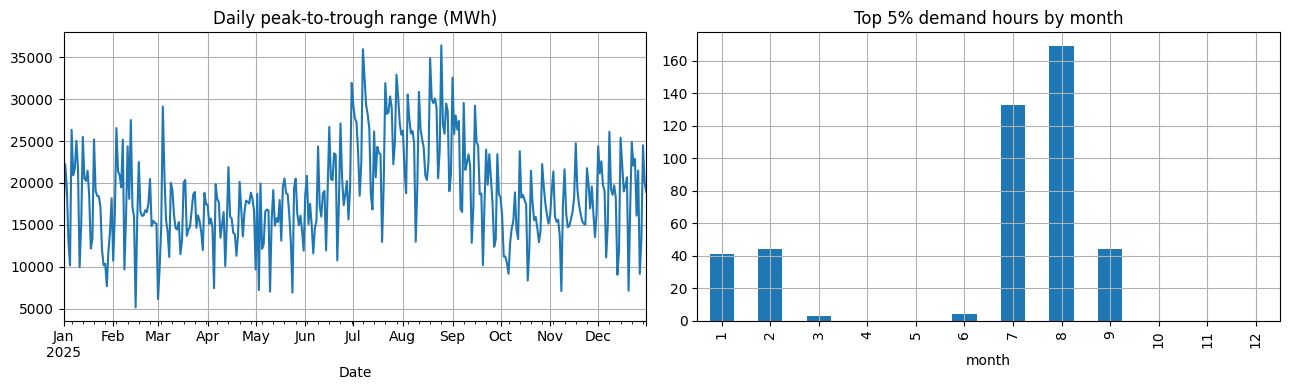

In [137]:
from pathlib import Path
out_dir=Path('results');out_dir.mkdir(exist_ok=True)
daily_ops=df.groupby('날짜').agg(avg_mwh=('demand_mwh','mean'),peak_mwh=('demand_mwh','max'),min_mwh=('demand_mwh','min'),std_mwh=('demand_mwh','std'))
daily_ops['range_mwh']=daily_ops.peak_mwh-daily_ops.min_mwh
daily_ops['range_ratio']=daily_ops.range_mwh/daily_ops.avg_mwh
peak_threshold=df.demand_mwh.quantile(.95)
df['top5_peak']=df.demand_mwh>=peak_threshold
peak_summary=df[df.top5_peak].groupby(['month','hour']).size().rename('hours').reset_index()
print('2025 top-5% threshold:',round(peak_threshold,1),'MWh; flagged hours:',int(df.top5_peak.sum()))
print('Peak hours by month:');display(df.groupby('month')['top5_peak'].agg(['sum','mean']).rename(columns={'sum':'peak_hours','mean':'peak_share'}).round(3))
print('Highest daily range:');display(daily_ops.nlargest(5,'range_mwh').round(1).reset_index())
fig,axes=plt.subplots(1,2,figsize=(13,4))
daily_ops['range_mwh'].plot(ax=axes[0],title='Daily peak-to-trough range (MWh)')
axes[0].set_xlabel('Date')  # 한글 폰트 미지원 환경에서 글자 깨짐 방지
df.groupby('month')['top5_peak'].sum().plot(kind='bar',ax=axes[1],title='Top 5% demand hours by month')
plt.tight_layout();plt.savefig(out_dir/'peak_volatility.png',dpi=140);plt.show()

## 7. 시간별 전력수요 급변 구간 분석

### 분석 목적

시간별 전력수요의 급격한 증감 구간 탐색 및 평상시 시간대별 변화 패턴과의 차이 분석

### 분석 방법

- **시간별 변화량 분석:** 직전 시간 대비 전력수요의 증가량과 감소량 계산
- **급변 구간 탐색:** 절대 변화량이 큰 시간대를 중심으로 주요 변동 구간 확인
- **시간대별 패턴 비교:** 동일한 시간대에서 일반적으로 발생하는 수요 변화 수준과 비교
- **상대적 변동성 평가:** 변화량의 크기뿐만 아니라 평상시 패턴 대비 차이를 함께 검토

### 결과 해석

절대 변화량이 크더라도 특정 시간대에 반복적으로 나타나는 일반적인 수요 변화일 수 있다.  
따라서 변화량 자체와 평상시 패턴 대비 상대적 차이를 함께 고려하여 급변 구간의 특성을 해석한다.

분석에서 확인된 급변 구간은 추가적인 모니터링이 필요한 후보 구간으로 활용할 수 있으며, 실제 전력설비의 이상이나 사고를 의미하지는 않는다.

Top 1% hourly change threshold: 6450.8 MWh


,timestamp,demand_mwh,delta_mwh,ramp_pct
128,2025-01-06 08:00:00,80157.0,8969.0,12.60
1496,2025-03-04 08:00:00,79627.0,8896.0,12.58
8527,2025-12-22 07:00:00,73580.0,8641.0,13.31
296,2025-01-13 08:00:00,83820.0,8482.0,11.26
464,2025-01-20 08:00:00,80585.0,8455.0,11.72
4496,2025-07-07 08:00:00,78894.0,8446.0,11.99
1016,2025-02-12 08:00:00,82816.0,8396.0,11.28
896,2025-02-07 08:00:00,85153.0,8309.0,10.81
200,2025-01-09 08:00:00,86700.0,8302.0,10.59
5696,2025-08-26 08:00:00,84299.0,8297.0,10.92


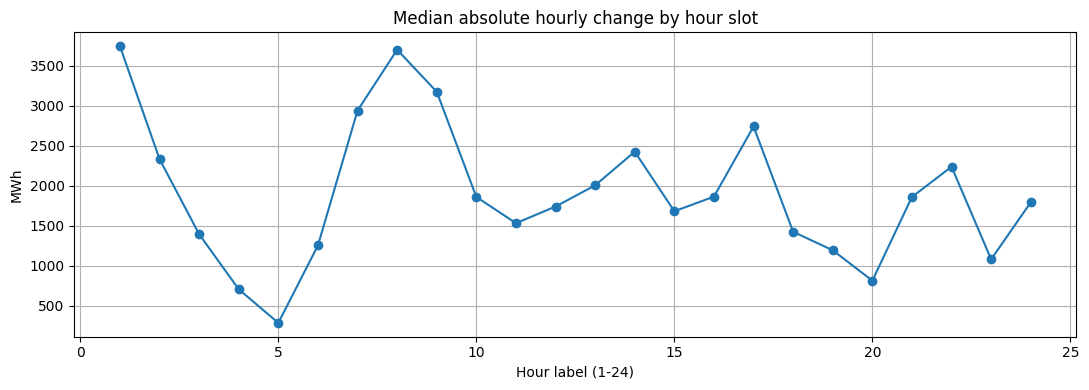

In [138]:
df['ramp_pct']=df.demand_mwh.pct_change()*100
ramp_threshold=df.abs_delta_mwh.quantile(.99)
df['top1_ramp']=df.abs_delta_mwh>=ramp_threshold
print('Top 1% hourly change threshold:',round(ramp_threshold,1),'MWh')
display(df.nlargest(12,'abs_delta_mwh')[['timestamp','demand_mwh','delta_mwh','ramp_pct']].round(2))
fig,ax=plt.subplots(figsize=(11,4))
df.groupby('hour')['abs_delta_mwh'].median().plot(ax=ax,marker='o')
ax.set(title='Median absolute hourly change by hour slot',xlabel='Hour label (1-24)',ylabel='MWh')
plt.tight_layout();plt.savefig(out_dir/'hourly_ramp.png',dpi=140);plt.show()

## 8. 시간대·요일별 이례 패턴 탐지

### 분석 목적

요일·시간대별 전력수요 기준을 활용한 평상시 수요 수준 대비 이례 구간 탐색

### 분석 방법

- **기준 데이터:** 1~9월 전력수요 데이터를 활용하여 요일·시간대별 기준값 산출
- **평가 데이터:** 10~12월 전력수요를 과거 기준값과 비교
- **통계적 기준:** 중앙값과 MAD(중앙절대편차)를 활용한 Robust Z-score 계산
- **이례 신호 탐지:** `|robust_z| >= 3.5`인 구간을 통계적 이례 신호로 분류
- **안정성 확보:** 미래 데이터의 기준값 반영을 방지하고, MAD가 0에 가까운 경우의 계산 오류 방지

### 결과 해석

1~9월 전체를 묶어 요일·시간대별 MAD를 산출하므로 계절 차이로 기준선이 넓어져 탐지가 둔감할 수 있다.  
공휴일을 별도 구분하지 않아 추석 등 연휴의 수요 변화를 정확히 설명하지 못하며, 임계값에 따른 결과 차이도 함께 확인해야 한다.

탐지된 구간은 동일한 요일·시간대의 일반적인 수요 수준에서 크게 벗어난 시점을 의미한다.  
다만 계절적 수요 변화도 탐지 결과에 영향을 줄 수 있으므로, 해당 신호를 실제 설비 장애나 운영 이상으로 단정하지 않는다.

Holdout context flags: 0 of 2208 hours


threshold,flagged_hours
2.0,49
2.5,23
3.0,0
3.5,0


timestamp,demand_mwh,median,mad,robust_z
2025-10-07 06:00:00,45139.0,63271.0,4160.0,-2.94
2025-10-08 03:00:00,44546.0,58877.0,3291.0,-2.94
2025-10-08 05:00:00,45230.0,59793.0,3380.0,-2.91
2025-10-08 04:00:00,44458.0,58611.0,3301.0,-2.89
2025-10-07 05:00:00,44303.0,59952.0,3669.0,-2.88
2025-10-08 02:00:00,45079.0,59605.0,3457.0,-2.83
2025-10-09 08:00:00,48606.0,73639.0,6030.0,-2.80
2025-10-08 06:00:00,46324.0,63462.0,4141.0,-2.79
2025-10-09 09:00:00,48153.0,73676.0,6281.0,-2.74
2025-10-07 04:00:00,43596.0,58538.0,3742.0,-2.69


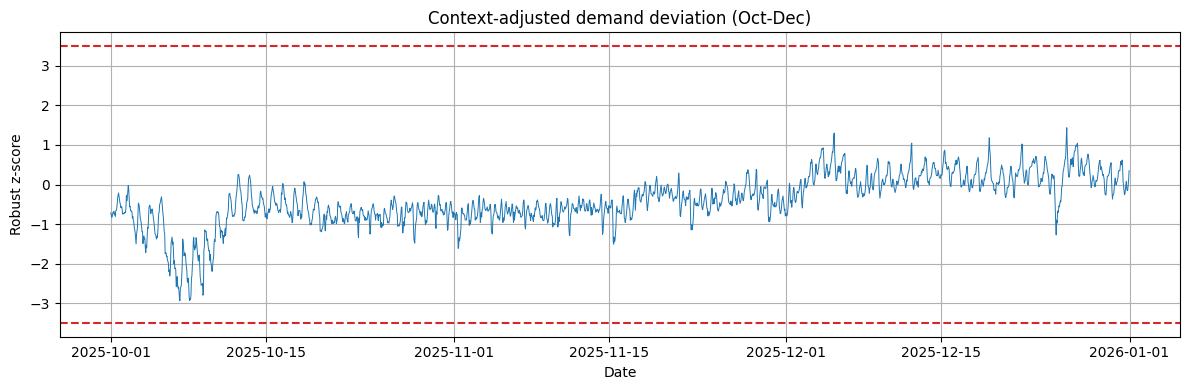

In [139]:
from IPython.display import HTML, display

reference=df[df.timestamp<'2025-10-01'].copy()
ref_stats=reference.groupby(['weekday','hour'])['demand_mwh'].agg(median='median').reset_index()
ref_mad=reference.merge(ref_stats,on=['weekday','hour'])
ref_mad['abs_dev']=(ref_mad.demand_mwh-ref_mad['median']).abs()
mad=ref_mad.groupby(['weekday','hour'])['abs_dev'].median().rename('mad').reset_index()

context=df.merge(ref_stats,on=['weekday','hour']).merge(mad,on=['weekday','hour'])
context['robust_z']=(context.demand_mwh-context['median'])/(1.4826*context['mad'].clip(lower=100))
context['context_flag']=context.robust_z.abs()>=3.5

holdout=context[context.timestamp>='2025-10-01'].copy()
print('Holdout context flags:',int(holdout.context_flag.sum()),'of',len(holdout),'hours')

display(HTML(pd.DataFrame([{'threshold':t,'flagged_hours':int((holdout.robust_z.abs()>=t).sum())} for t in [2.0,2.5,3.0,3.5]]).to_html(index=False)))

display(HTML(holdout.assign(abs_z=holdout.robust_z.abs()).nlargest(12,'abs_z')[['timestamp','demand_mwh','median','mad','robust_z']].round(2).to_html(index=False)))

fig,ax=plt.subplots(figsize=(12,4))
ax.plot(holdout.timestamp,holdout.robust_z,lw=.7)
ax.axhline(3.5,color='tab:red',ls='--')
ax.axhline(-3.5,color='tab:red',ls='--')
ax.set(title='Context-adjusted demand deviation (Oct-Dec)',ylabel='Robust z-score',xlabel='Date')
plt.tight_layout()
plt.savefig(out_dir/'context_deviation.png',dpi=140)
plt.show()

## 9. 시간대·요일별 예측 오차 분석

### 분석 개요

12월 테스트 데이터를 활용한 최종 머신러닝 모델의 시간대·요일별 예측 오차 분석 및 개선 필요 구간 파악

### 분석 항목

- **평균 절대오차(MAE):** 실제 전력수요와 예측값의 차이를 기준으로 예측 정확도 평가
- **시간대별 오차:** 시간대별 평균 절대오차를 산출하여 예측이 상대적으로 어려운 시간대 확인
- **요일별 오차:** 요일별 평균 절대오차를 비교하여 평일과 주말을 포함한 요일별 예측 성능 분석

### 분석 결과 활용

시간대와 요일에 따른 예측 오차의 차이를 확인하여 모델의 취약 구간을 파악하고, 추가적인 입력 변수 도입이나 모델 개선 방향을 검토한다.

다만 분석 결과는 12월 테스트 데이터에 한정되므로, 다른 계절이나 전체 기간의 예측 성능을 대표하는 것으로 해석하지 않는다.

Top prediction errors:


,timestamp,hour,weekday,demand_mwh,prediction,absolute_error,baseline_error,previous_day_error
8509,2025-12-21 13:00:00,14,6,49574.0,53733.8,4159.8,1943.0,12516.0
8632,2025-12-26 16:00:00,17,4,81379.0,77431.3,3947.7,4216.0,13440.0
8530,2025-12-22 10:00:00,11,0,74651.0,78389.7,3738.7,4893.0,18762.0
8200,2025-12-08 16:00:00,17,0,77608.0,73916.6,3691.4,4340.0,18231.0
8411,2025-12-17 11:00:00,12,2,70568.0,74226.5,3658.5,3399.0,9382.0
8194,2025-12-08 10:00:00,11,0,70639.0,73945.5,3306.5,4099.0,18991.0
8723,2025-12-30 11:00:00,12,1,68841.0,72001.4,3160.4,4639.0,5734.0
8460,2025-12-19 12:00:00,13,4,68963.0,72097.3,3134.3,5821.0,5708.0
8079,2025-12-03 15:00:00,16,2,78182.0,75145.1,3036.9,3883.0,4733.0
8695,2025-12-29 07:00:00,8,0,69923.0,66887.5,3035.5,7524.0,10362.0


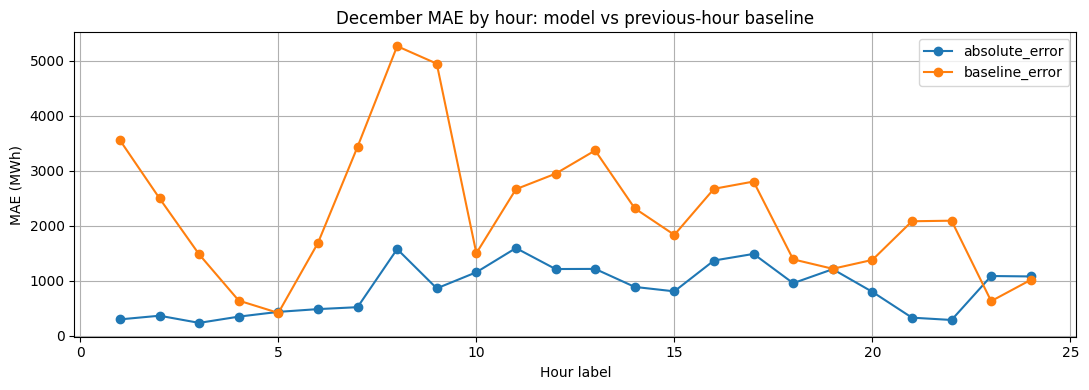

Weekday error summary:


,mean,max,count
weekday,,,
0,957.3,3738.7,120
1,792.5,3160.4,120
2,868.1,3658.5,120
3,852.4,2667.9,96
4,952.8,3947.7,96
5,802.8,2550.8,96
6,788.4,4159.8,96


In [140]:
errors=test[['timestamp','hour','weekday','demand_mwh']].copy()
errors['prediction']=np.asarray(pred)
errors['absolute_error']=(errors.demand_mwh-errors.prediction).abs()
errors['baseline_error']=(test.demand_mwh-test.lag_1).abs().to_numpy()
errors['previous_day_error']=(test.demand_mwh-test.lag_24).abs().to_numpy()
print('Top prediction errors:');display(errors.nlargest(10,'absolute_error').round(1))
by_hour=errors.groupby('hour')[['absolute_error','baseline_error']].mean()
fig,ax=plt.subplots(figsize=(11,4))
by_hour.plot(ax=ax,marker='o');ax.set(title='December MAE by hour: model vs previous-hour baseline',ylabel='MAE (MWh)',xlabel='Hour label')
plt.tight_layout();plt.savefig(out_dir/'model_error_by_hour.png',dpi=140);plt.show()
print('Weekday error summary:');display(errors.groupby('weekday')['absolute_error'].agg(['mean','max','count']).round(1))

## 10. 분석 결과 종합 및 운영 활용 방안

### 분석 결과 종합

2025년 전국 시간별 전력수요 데이터를 분석하여 다음과 같은 주요 특성을 확인하였다.

- **피크 수요:** 상위 5% 전력수요가 가장 많이 발생한 달은 8월이며, 시간대별로는 17시와 18시에 각각 55시간 발생하였다.
- **일별 변동성:** 8월 25일에 하루 최고·최저 전력수요 차이가 가장 크게 나타났다.
- **평일·주말 차이:** 평일 평균 전력수요는 66,920.9 MWh, 주말 평균은 58,435.9 MWh로 나타났다.
- **이례 신호:** 10~12월 데이터에서 설정한 기준(|Robust Z-score| ≥ 3.5)에 해당하는 이례 신호는 검출되지 않았다.

### 운영 활용 방안

- **수요 패턴 모니터링:** 월별·요일별·시간대별 수요 특성을 활용한 모니터링 기준 설정
- **피크 및 급변 구간 관리:** 최대 수요 집중 구간과 급격한 수요 변화에 대한 관찰 지표 활용
- **이례 신호 탐색:** 통계적 기준선을 벗어나는 수요 구간의 추가 분석
- **예측 모델 개선:** 시간대·요일별 예측 오차를 활용한 모델 성능 점검 및 개선 방향 도출

### 활용 범위 및 한계

본 분석에서 도출한 전력수요 패턴과 피크·변동성 지표, 이례 신호는 전력수요 모니터링 및 추가 분석에 활용할 수 있다.

다만 이례 신호가 실제 설비 장애나 운영 위험을 의미하지는 않으며, 제시한 활용 방안은 실무 환경에서 검증되지 않았다.

In [141]:
daily_ops.to_csv(out_dir/'daily_operational_indicators.csv',encoding='utf-8-sig')
val_table.to_csv(out_dir/'validation_model_comparison.csv',index=False,encoding='utf-8-sig')
final_table.to_csv(out_dir/'december_model_comparison.csv',index=False,encoding='utf-8-sig')

print('분석 결과 CSV 파일 저장 완료')

분석 결과 CSV 파일 저장 완료


## 11. 분석 방법 선정 근거 및 한계

### 분석 방법 선정 근거

- **데이터 전처리:** 결측치와 중복값 검증 및 시간별 데이터 구조 변환을 통한 분석의 일관성 확보
- **시계열 패턴 분석:** 월별·요일별·시간대별 수요 비교를 통한 전력수요의 주기적 특성 파악
- **피크 및 변동성 분석:** 평균 수요만으로 확인하기 어려운 최대 수요 집중 구간과 시간별 급변 구간 탐색
- **통계적 이례 신호 탐지:** 요일·시간대별 중앙값과 MAD를 활용한 평상시 수요 패턴 대비 이례 구간 탐색
- **머신러닝 모델 비교:** Ridge, Random Forest, Hist Gradient Boosting 모델을 활용한 전력수요 예측 성능 비교
- **시간순 데이터 분할:** 1~9월 학습, 10~11월 검증, 12월 최종 평가로 구분하여 미래 데이터의 학습 유입 방지

### 분석의 기술적 한계

- **데이터 범위:** 2025년 단일 연도 자료로 장기적인 전력수요 변화와 연도별 차이 분석에 한계
- **외부 변수 미반영:** 기온·습도·공휴일 등 전력수요에 영향을 줄 수 있는 외부 변수의 반영 부족
- **이례 신호 탐지:** 1~9월 통합 기준선 산출로 계절적 차이에 따른 탐지 민감도 저하 가능성
- **예측 모델의 전제:** 예측 시점에 직전 시간의 실제 전력수요를 확보할 수 있다고 가정
- **성능 평가 범위:** 12월 데이터에 한정된 최종 성능으로 다른 계절 및 장기 예측 상황에 대한 일반화 한계